In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [9]:
df=pd.read_csv('/content/sample_data/CAR DETAILS FROM CAR DEKHO.csv')

In [10]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [11]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [13]:
df.shape

(4340, 8)

In [15]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [16]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


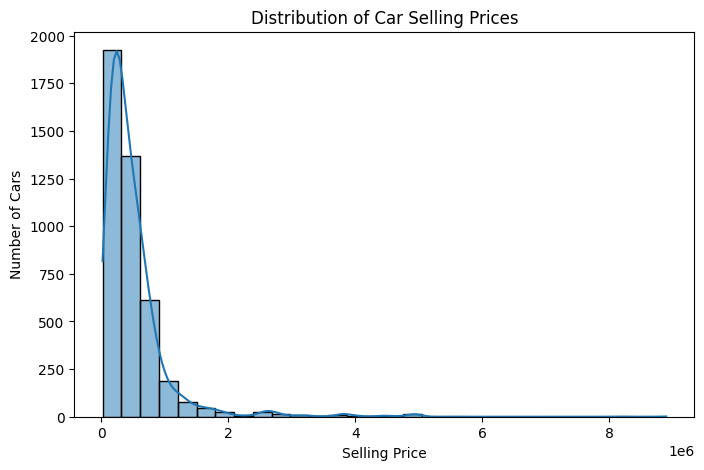

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="selling_price", bins=30, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

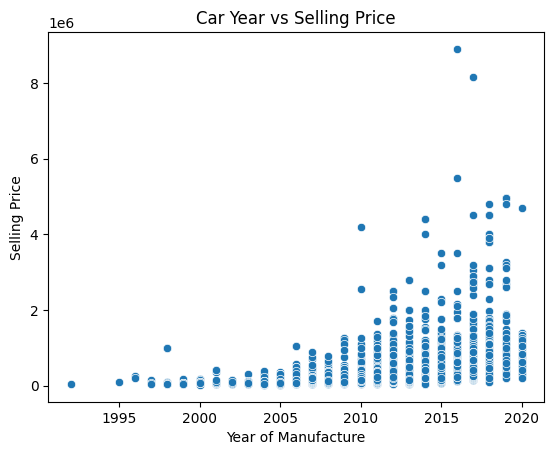

In [18]:
sns.scatterplot(data=df, x="year", y="selling_price")

plt.title("Car Year vs Selling Price")
plt.xlabel("Year of Manufacture")
plt.ylabel("Selling Price")

plt.show()

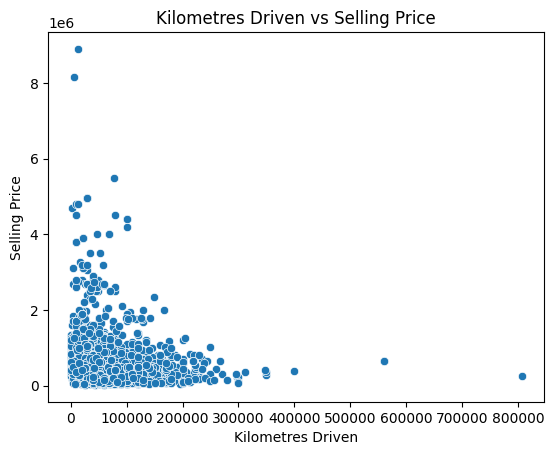

In [19]:
sns.scatterplot(data=df, x="km_driven", y="selling_price")

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.show()

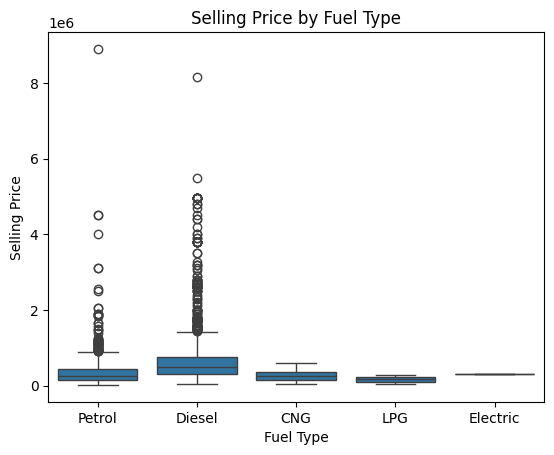

In [20]:
sns.boxplot(data=df, x="fuel", y="selling_price")

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.show()

In [21]:
X = df[
    ["year", "km_driven", "fuel",
     "seller_type", "transmission", "owner"]
]


In [22]:
y = df["selling_price"]


In [23]:
print(X.head())

   year  km_driven    fuel seller_type transmission         owner
0  2007      70000  Petrol  Individual       Manual   First Owner
1  2007      50000  Petrol  Individual       Manual   First Owner
2  2012     100000  Diesel  Individual       Manual   First Owner
3  2017      46000  Petrol  Individual       Manual   First Owner
4  2014     141000  Diesel  Individual       Manual  Second Owner


In [25]:
print(y.head())

0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64


In [26]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3472, 6)
Testing data: (868, 6)


In [27]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Numerical columns
numeric_features = ["year", "km_driven"]

# Categorical columns
categorical_features = [
    "fuel", "seller_type", "transmission", "owner"
]

# Convert categories into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

# Combine preprocessing and Linear Regression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Preprocessing is ready!")

Preprocessing is ready!


In [28]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [29]:

y_pred = model.predict(X_test)
print("Predicted prices:")
print(y_pred[:10])

print("\nActual prices:")
print(y_test.iloc[:10].to_list())

Predicted prices:
[ 429791.44395418  504490.85855359   60211.17118469  475380.44208416
 1519809.14934851  226071.998254    444068.63087741  255872.36232163
  648609.79806618  308855.00051504]

Actual prices:
[165000, 250000, 120000, 450000, 730000, 155000, 530000, 92800, 284000, 260000]


In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [31]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)


In [32]:
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


In [33]:
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


MAE: 221706.37
MSE: 182146878750.31
RMSE: 426786.69
R2 Score: 0.4031


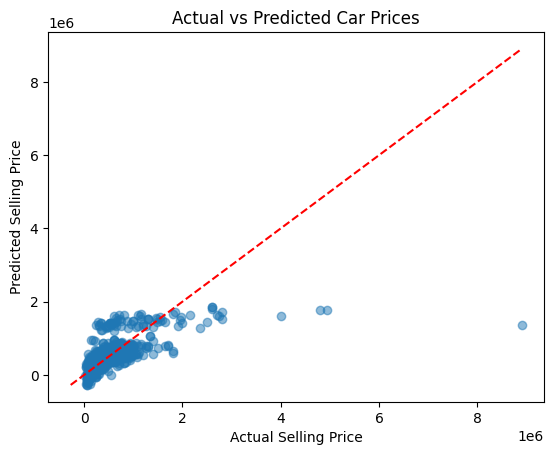

In [34]:
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

# Reference line for perfect predictions
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(limits, limits, "r--")

plt.show()

In [35]:

# Include the car name as an additional feature
X = df[
    ["name", "year", "km_driven", "fuel",
     "seller_type", "transmission", "owner"]
]

y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Add name to the categorical features
numeric_features = ["year", "km_driven"]

categorical_features = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluate
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

MAE: 221203.46
RMSE: 426356.03
R2 Score: 0.4043


In [36]:

# Create a new feature
df["car_age"] = 2026 - df["year"]

X = df[
    ["name", "car_age", "km_driven", "fuel",
     "seller_type", "transmission", "owner"]
]

y = df["selling_price"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_features = ["car_age", "km_driven"]

categorical_features = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

MAE: 221203.46
RMSE: 426356.03
R2 Score: 0.4043
